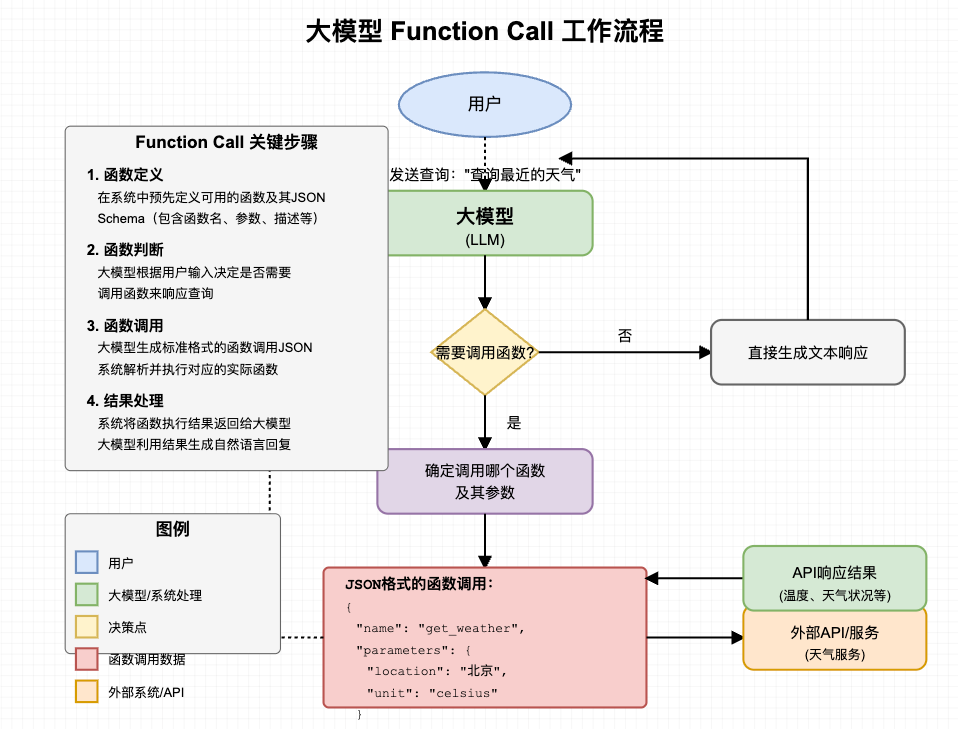

## Function Calling

功能：模型本身并不直接执行函数，而是根据用户的输入，决定“何时”以及“如何”调用一个函数，并输出结构化调用请求。

主要用途：让 AI 能够连接外部世界，比如查询实时信息、操作数据库、发送邮件，或者把自然语言指定转换为对 API 的调用。

## Function Calling 核心流程总结

Function Calling = 大模型负责决策 + 程序负责执行 + 执行结果反馈给大模型，循环直到生成最终回答。

当 LLM 决定调用工具时，通常会结束当前这一次 API 响应，将工具调用请求返回给 Python 程序。但是要注意：停止的是本次模型生成，不是整个 Function Calling 流程。

下面给了一个案例，获取天气，其中有两个工具，获取日期和天气。

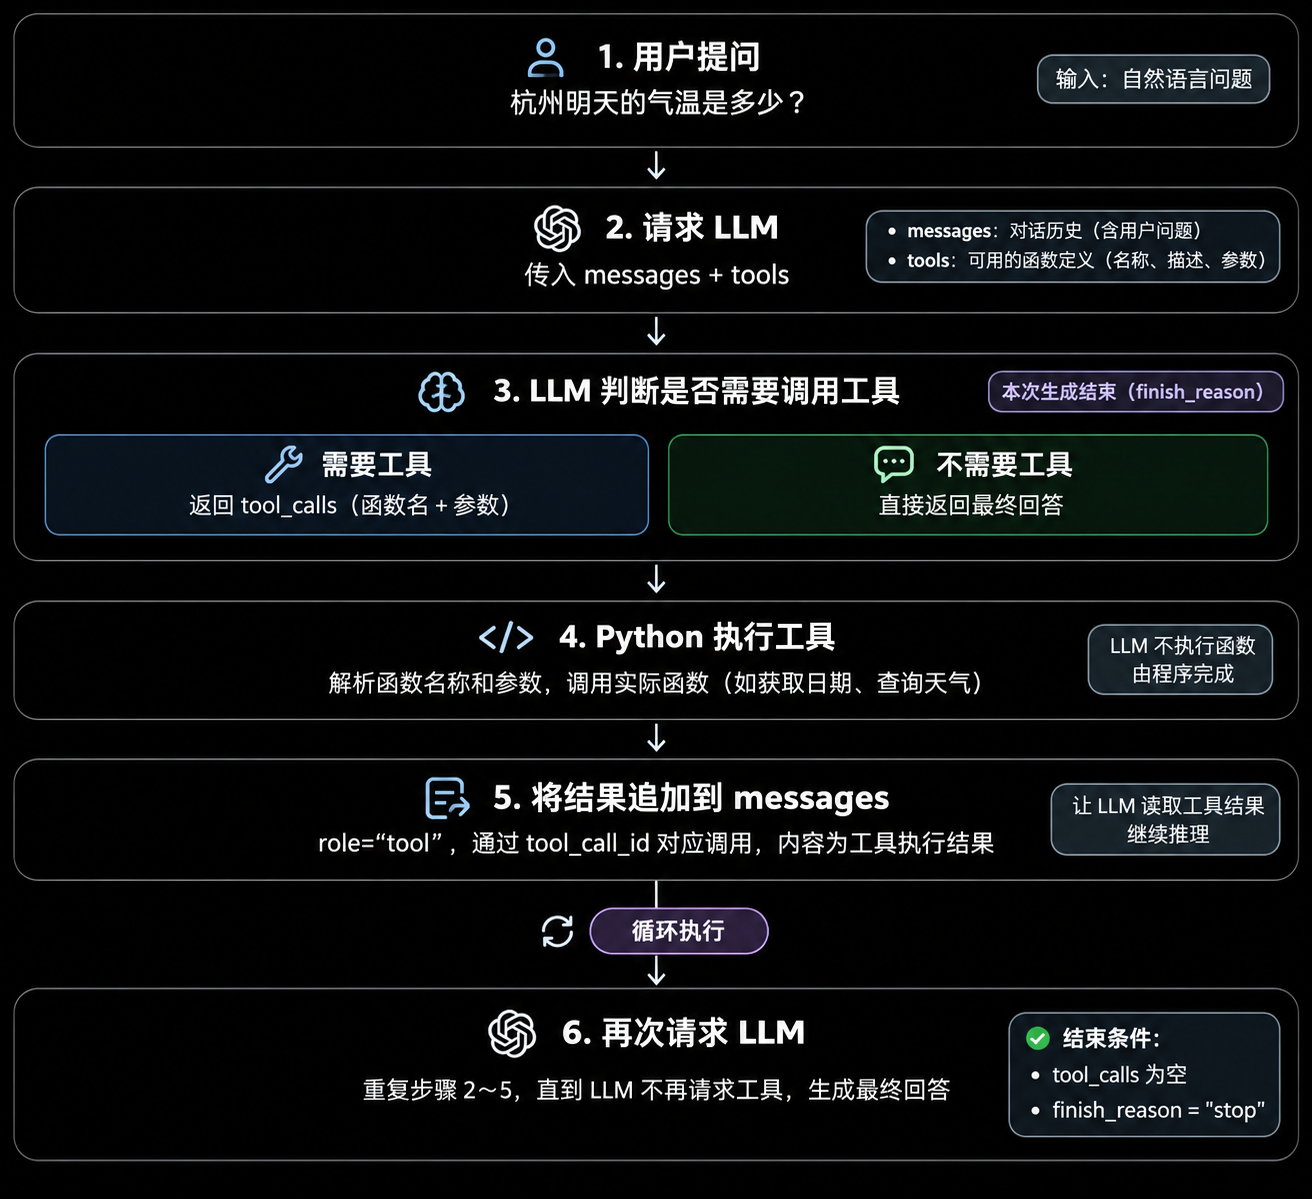

In [12]:
import json
import requests
from openai import OpenAI
from datetime import datetime, date as date_type

'''
    1、先准备两个工具函数，分别是获取当前日期和获取指定位置的气温。
'''
def get_date_mock() -> str:
    return datetime.now().strftime("%Y-%m-%d")

def get_weather_mock(location, date: str) -> str:
    """
    获取指定位置的气温：
    current：当前气温
    YYYY-MM-DD：指定日期的平均气温
    """

    longitude = location.get("longitude")
    latitude = location.get("latitude")
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "timezone": "auto",
    }

    if date == "current":
        url = "https://api.open-meteo.com/v1/forecast"
        params["current"] = "temperature_2m"
    else:
        target_date = date_type.fromisoformat(date)

        if target_date < date_type.today():
            url = "https://archive-api.open-meteo.com/v1/archive"
        else:
            url = "https://api.open-meteo.com/v1/forecast"

        params["start_date"] = date
        params["end_date"] = date
        params["daily"] = "temperature_2m_mean"

    response = requests.get(url, params=params, timeout=10)
    response.raise_for_status()
    data = response.json()

    if data.get("error"):
        raise ValueError(data.get("reason", "天气查询失败"))

    if date == "current":
        return str(data["current"]["temperature_2m"])

    return str(data["daily"]["temperature_2m_mean"][0])

'''
    2、定义工具函数的映射关系，方便后续根据工具名称调用对应的函数。
'''
TOOL_CALL_MAP = {
    "get_date": get_date_mock,
    "get_weather": get_weather_mock,
}

'''
    3、tools 参数
        Function Calling 主要借助 OpenAI client.chat.completions.create() 的 tools 参数来实现，tools 参数是一个列表，每个元素都是一个字典，
        字典中包含了函数的定义信息，包括函数名、描述、参数等。是有规范的，不是随意定义的。下面是一个示例，定义了两个函数：get_date 和 get_weather。
'''
tools = [
    {
        "type": "function",
        "function": {
            "name": "get_date",
            "description": "Get the current date",
            "parameters": {
                "type": "object",
                "properties": {}
            }
        }
    },
    {
        "type": "function",
        "function": {
            "name": "get_weather",
            "description": "Get the weather forecast for a location and date.",
            "parameters": {
                "type": "object",
                "properties": {
                    "location": {
                        "type": "object",
                        "description": "City coordinates",
                        "properties": {
                            "latitude": {
                                "type": "number",
                                "description": "Latitude"
                            },
                            "longitude": {
                                "type": "number",
                                "description": "Longitude"
                            }
                        },
                        "required": ["latitude", "longitude"]
                    },
                    "date": {
                        "type": "string",
                        "description": "Date in YYYY-MM-DD format"
                    }
                },
                "required": ["location", "date"]
            }
        }
    }
]


def run_turn(turn, messages):
    sub_turn = 1
    while True:
        response = client.chat.completions.create(
            model='deepseek-flash',
            messages=messages,
            tools=tools,  # 传入工具函数定义
            reasoning_effort="high",
            # extra_body={ "thinking": { "type": "enabled" } },
        )

        '''
        4、获取模型的推理内容、最终回答和工具调用信息
            response.choices[0].message.reasoning_content：模型的推理内容，包含了模型在思考过程中使用的工具函数和参数。
            response.choices[0].message.content：模型的最终回答。
            response.choices[0].message.tool_calls：模型调用的工具函数信息，包含了函数名、参数等。
        '''
        messages.append(response.choices[0].message)
        reasoning_content = response.choices[0].message.reasoning_content
        content = response.choices[0].message.content
        tool_calls = response.choices[0].message.tool_calls # 获取 tool calls
        print(f"Turn {turn}.{sub_turn}\n{reasoning_content=}\n{content=}\n{tool_calls=}")

        # If there is no tool calls, then the model should get a final answer and we need to stop the loop
        if tool_calls is None:
            break

        for tool in tool_calls:
            # Call the tool function and get the result
            tool_function = TOOL_CALL_MAP[tool.function.name]
            tool_result = tool_function(**json.loads(tool.function.arguments))
            print(f"tool result for {tool.function.name}: {tool_result}\n")

            '''
            5、将工具调用的结果添加到消息列表中，作为下一轮模型推理的输入
                messages.append({
                    "role": "tool",
                    "tool_call_id": tool.id,
                    "content": tool_result,
                })
            '''
            messages.append({
                "role": "tool",
                "tool_call_id": tool.id,
                "content": tool_result,
            })

        sub_turn += 1
    print()


client = OpenAI(api_key='sk-54c8ff13fe1b482eb667c6d13e2f2df7', base_url='https://api.deepseek.com')

# The user starts a question
turn = 1
messages = [
    {
        "role": "assistant",
        "content": "Use Chinse to answer the question.",
    },
    {
        "role": "user",
        "content": "How's the weather in Hangzhou Tomorrow",
    }
]
run_turn(turn, messages)

# The user starts a new question
turn = 2
messages.append({
    "role": "user",
    "content": "How's the weather in Guangzhou Tomorrow",
})
run_turn(turn, messages)

Turn 1.1
reasoning_content='The user asks about the weather in Hangzhou tomorrow. I need the current date and Hangzhou coordinates (30.2741, 120.1551). Let me call get_date and get_weather... but get_weather needs the date, which depends on get_date. So first get the date.'
content=''
tool_calls=[ChatCompletionMessageFunctionToolCall(id='call_00_6Le9UGP8ZPeMziCHOy7I7546', function=Function(arguments='{}', name='get_date'), type='function', index=0)]
tool result for get_date: 2026-11-03

Turn 1.2
reasoning_content='Today is 2026-11-03, so tomorrow is 2026-11-04. Call get_weather for Hangzhou.'
content=''
tool_calls=[ChatCompletionMessageFunctionToolCall(id='call_00_15UCkv6jXFSu87ErbwNd5554', function=Function(arguments='{"location": {"latitude": 30.2741, "longitude": 120.1551}, "date": "2026-11-04"}', name='get_weather'), type='function', index=0)]
tool result for get_weather: 17.3

Turn 1.3
reasoning_content='The tool returned just "17.3" — presumably temperature in Celsius. Let me rep